# DSCI 552 Homework 4

**Jun Jiang** · GitHub: `generalisjj-hub`
## 2. Time Series Classification Part 2: Binary and Multiclass Classification

Homework 4 uses the fixed AReM split from Homework 3: datasets 1--2 from
`bending1` and `bending2`, and datasets 1--3 from every other activity, are
the test set.  The remaining instances are the training set.

In [1]:
from __future__ import annotations

from itertools import combinations
from pathlib import Path
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE, RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    auc,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import PerfectSeparationError


DATA_ROOT = Path("data/AReM")
if not DATA_ROOT.exists():
    DATA_ROOT = Path("../data/AReM")
ACTIVITIES = (
    "bending1",
    "bending2",
    "cycling",
    "lying",
    "sitting",
    "standing",
    "walking",
)
SIGNALS = (
    "avg_rss12",
    "var_rss12",
    "avg_rss13",
    "var_rss13",
    "avg_rss23",
    "var_rss23",
)
TEST_LAST_DATASET = {
    "bending1": 2,
    "bending2": 2,
    "cycling": 3,
    "lying": 3,
    "sitting": 3,
    "standing": 3,
    "walking": 3,
}
EXPECTED_TIMES = pd.Index(np.arange(0, 120_000, 250), name="time")
STATISTICS = ("min", "max", "mean", "median", "std", "q1", "q3")
L_VALUES = tuple(range(1, 21))
RANDOM_STATE = 552


def dataset_number(path: Path) -> int:
    match = re.fullmatch(r"dataset(\d+)", path.stem)
    if match is None:
        raise ValueError(f"Unexpected AReM file name: {path.name}")
    return int(match.group(1))


def read_instance(path: Path) -> pd.DataFrame:
    """Load an AReM file while handling its small delimiter/row defects."""
    rows = [
        re.split(r"[\s,]+", line.strip())
        for line in path.read_text().splitlines()
        if line.strip() and not line.startswith("#")
    ]
    frame = pd.DataFrame(rows).replace("", np.nan).dropna(axis=1, how="all")
    if frame.shape[1] != 7:
        raise ValueError(f"{path} has {frame.shape[1]} columns; expected 7.")

    frame.columns = ("time", *SIGNALS)
    frame = frame.apply(pd.to_numeric, errors="raise")
    if frame["time"].duplicated().any() or not frame["time"].isin(EXPECTED_TIMES).all():
        raise ValueError(f"Unexpected timestamps in {path}")

    frame = frame.set_index("time").reindex(EXPECTED_TIMES)
    frame[list(SIGNALS)] = frame[list(SIGNALS)].interpolate(
        method="index", limit_area="inside"
    )
    if frame[list(SIGNALS)].isna().any().any():
        raise ValueError(f"Missing non-interior data in {path}")
    return frame.reset_index()


def load_instances() -> list[dict[str, object]]:
    instances: list[dict[str, object]] = []
    for activity in ACTIVITIES:
        files = sorted((DATA_ROOT / activity).glob("dataset*.csv"), key=dataset_number)
        if not files:
            raise FileNotFoundError(f"No files found for {activity}")
        for path in files:
            number = dataset_number(path)
            instances.append(
                {
                    "activity": activity,
                    "dataset": number,
                    "split": "test" if number <= TEST_LAST_DATASET[activity] else "train",
                    "series": read_instance(path),
                }
            )
    if len(instances) != 88:
        raise ValueError(f"Expected 88 instances, found {len(instances)}")
    return instances


def feature_name(signal: str, segment: int, statistic: str) -> str:
    return f"{signal}__segment{segment}__{statistic}"


def segmented_feature_table(instances: list[dict[str, object]], n_segments: int) -> pd.DataFrame:
    """Extract the seven required time-domain features for every signal segment."""
    rows: list[dict[str, object]] = []
    for instance_number, instance in enumerate(instances, start=1):
        series = instance["series"]
        assert isinstance(series, pd.DataFrame)
        activity = str(instance["activity"])
        row: dict[str, object] = {
            "instance": instance_number,
            "activity": activity,
            "dataset": int(instance["dataset"]),
            "split": str(instance["split"]),
            "bending": int(activity.startswith("bending")),
        }
        for signal in SIGNALS:
            for segment_number, segment in enumerate(
                np.array_split(series[signal].to_numpy(dtype=float), n_segments), start=1
            ):
                row[feature_name(signal, segment_number, "min")] = float(np.min(segment))
                row[feature_name(signal, segment_number, "max")] = float(np.max(segment))
                row[feature_name(signal, segment_number, "mean")] = float(np.mean(segment))
                row[feature_name(signal, segment_number, "median")] = float(np.median(segment))
                row[feature_name(signal, segment_number, "std")] = float(
                    np.std(segment, ddof=1)
                )
                row[feature_name(signal, segment_number, "q1")] = float(
                    np.quantile(segment, 0.25)
                )
                row[feature_name(signal, segment_number, "q3")] = float(
                    np.quantile(segment, 0.75)
                )
        rows.append(row)
    return pd.DataFrame(rows)


def feature_columns(table: pd.DataFrame) -> list[str]:
    metadata = {"instance", "activity", "dataset", "split", "bending"}
    return [column for column in table.columns if column not in metadata]


RAW_INSTANCES = load_instances()
FEATURE_TABLES = {
    n_segments: segmented_feature_table(RAW_INSTANCES, n_segments)
    for n_segments in L_VALUES
}

for n_segments, table in FEATURE_TABLES.items():
    assert table.shape[0] == 88
    assert len(feature_columns(table)) == 42 * n_segments
    assert table[feature_columns(table)].notna().all().all()

split_summary = (
    FEATURE_TABLES[1]
    .groupby(["activity", "split"], sort=False)
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["train", "test"], fill_value=0)
)
assert int(split_summary["train"].sum()) == 69
assert int(split_summary["test"].sum()) == 19
display(split_summary)

split,train,test
activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3


### 2(a)(i) Scatter plots for the three Homework 3 features

The selected features are minimum, mean, and maximum.  The plots below use
time series 1, 2, and 6 (`avg_rss12`, `var_rss12`, and `var_rss23`) from the
training set and color bending versus other activities.

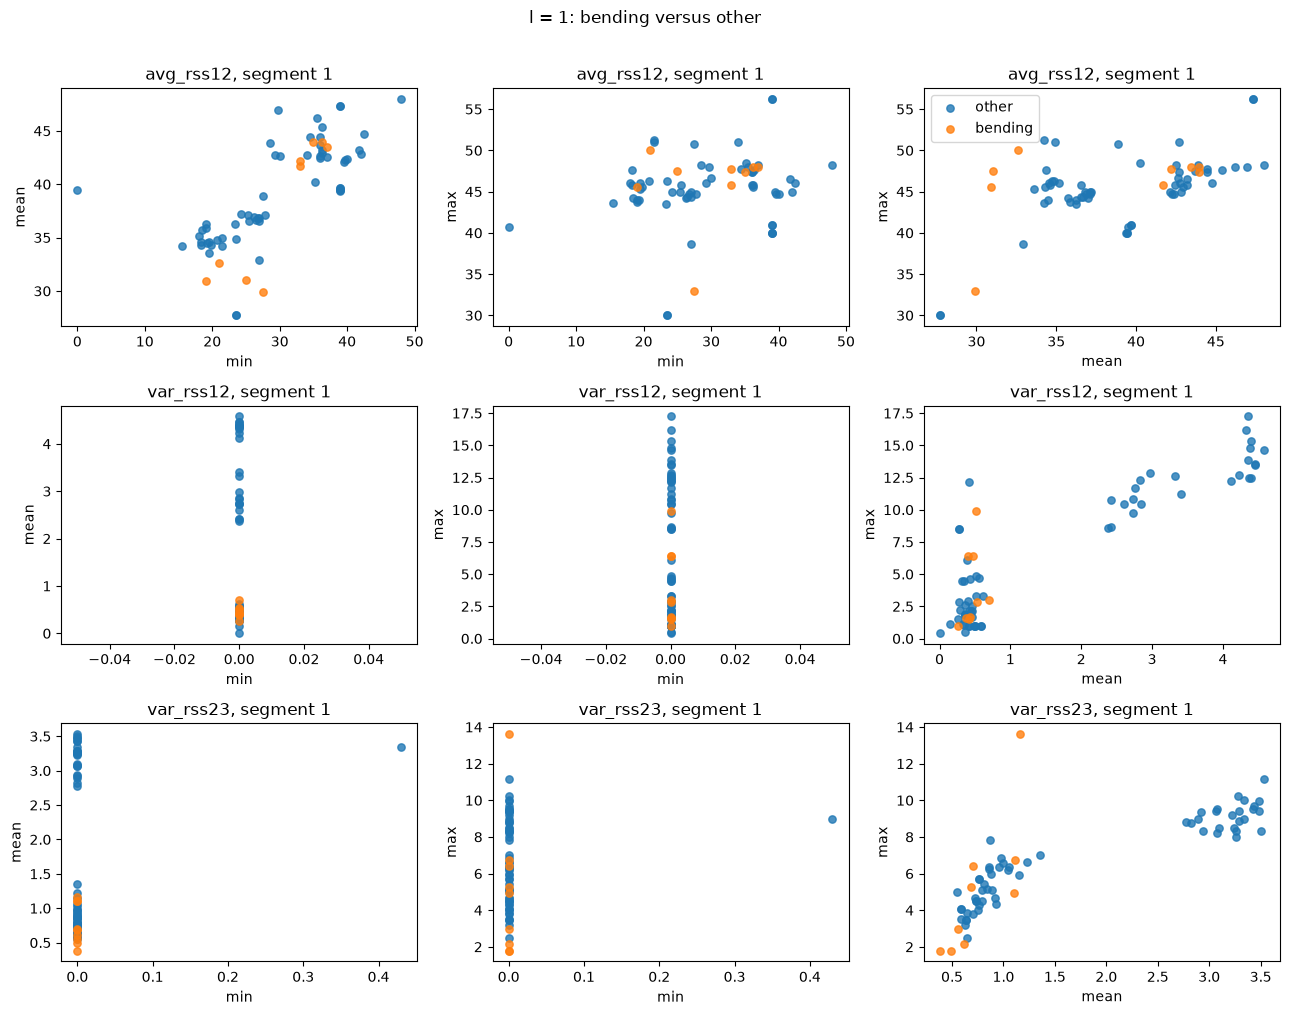

In [2]:
SCATTER_SIGNALS = (SIGNALS[0], SIGNALS[1], SIGNALS[5])
SCATTER_STATS = ("min", "mean", "max")


def plot_scatter_pairs(table: pd.DataFrame, segment: int, title: str) -> None:
    pairs = tuple(combinations(SCATTER_STATS, 2))
    fig, axes = plt.subplots(len(SCATTER_SIGNALS), len(pairs), figsize=(13, 10))
    for row_index, signal in enumerate(SCATTER_SIGNALS):
        for column_index, (x_stat, y_stat) in enumerate(pairs):
            axis = axes[row_index, column_index]
            x_column = feature_name(signal, segment, x_stat)
            y_column = feature_name(signal, segment, y_stat)
            for bending, color, label in ((0, "tab:blue", "other"), (1, "tab:orange", "bending")):
                subset = table[table["bending"] == bending]
                axis.scatter(
                    subset[x_column],
                    subset[y_column],
                    s=28,
                    alpha=0.8,
                    color=color,
                    label=label,
                )
            axis.set_xlabel(x_stat)
            axis.set_ylabel(y_stat)
            axis.set_title(f"{signal}, segment {segment}")
            if row_index == 0 and column_index == len(pairs) - 1:
                axis.legend()
    fig.suptitle(title, y=1.01)
    fig.tight_layout()
    plt.show()


train_l1 = FEATURE_TABLES[1].query("split == 'train'").reset_index(drop=True)
plot_scatter_pairs(train_l1, segment=1, title="l = 1: bending versus other")

### 2(a)(ii) Scatter plots after splitting each series in two

Splitting exposes within-record variation: for `var_rss23`, a bending
instance has a maximum of 13.61 in the first half and 6.02 in the second.
For `var_rss12`, bending observations tend to have low means
both before and after splitting, but they overlap with some other activities;
the plots do not show complete separation.

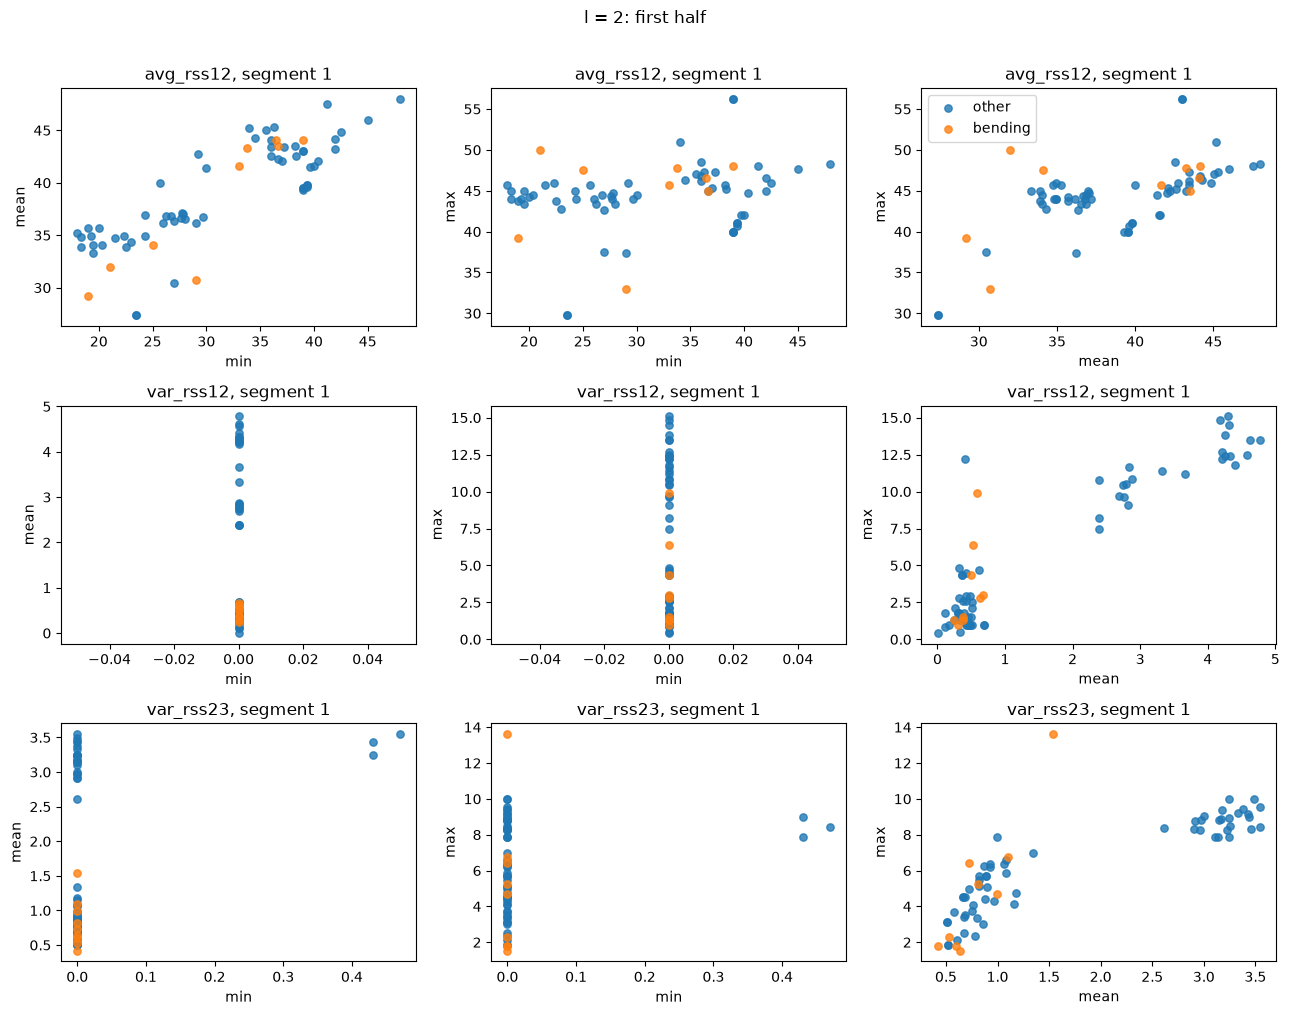

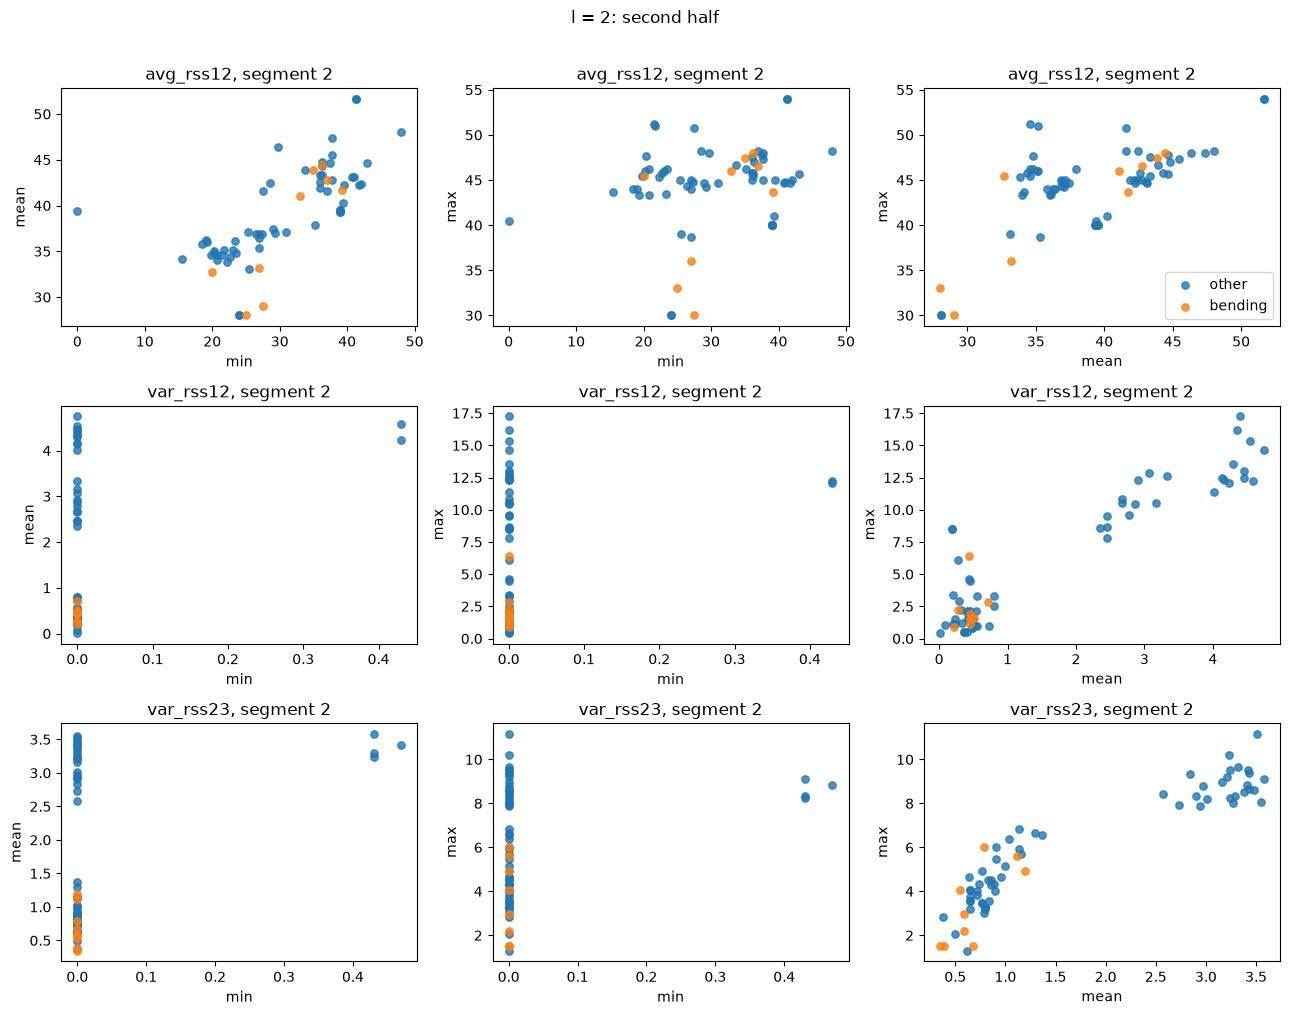

In [3]:
train_l2 = FEATURE_TABLES[2].query("split == 'train'").reset_index(drop=True)
plot_scatter_pairs(train_l2, segment=1, title="l = 2: first half")
plot_scatter_pairs(train_l2, segment=2, title="l = 2: second half")

### 2(a)(iii) Unpenalized logistic regression with RFE and 5-fold CV

For each value of `l`, RFECV scores candidate numbers of retained features
`p`. The highest mean CV accuracy is selected; ties use the smaller `p`.
RFE is then refit on all 69 training observations at that selected size.
Scaling and RFE are fit only inside each CV training fold. The wrong approach
would select or scale using all 69 training observations before the folds, or
use the test set while choosing `(l, p)`; both leak validation/test information.
Stratified 5-fold CV is used because bending is the rare binary class.

In [4]:
BINARY_CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def unpenalized_binary_logistic() -> LogisticRegression:
    # C=1e6 makes the built-in L2 penalty negligible for this exercise.
    return LogisticRegression(
        C=1e6,
        solver="liblinear",
        max_iter=10_000,
        random_state=RANDOM_STATE,
    )


def rfe_estimator() -> Pipeline:
    return Pipeline(
        [
            ("scale", StandardScaler()),
            ("logit", unpenalized_binary_logistic()),
        ]
    )


def rfe_selector() -> RFECV:
    return RFECV(
        estimator=rfe_estimator(),
        step=0.25,
        min_features_to_select=1,
        cv=BINARY_CV,
        scoring="accuracy",
        importance_getter="named_steps.logit.coef_",
        n_jobs=1,
    )


def fixed_rfe(n_features: int) -> RFE:
    return RFE(
        estimator=rfe_estimator(),
        n_features_to_select=n_features,
        step=0.25,
        importance_getter="named_steps.logit.coef_",
    )


rfe_selectors: dict[int, RFE] = {}
rfe_rows: list[dict[str, float | int]] = []
for n_segments in L_VALUES:
    train_table = FEATURE_TABLES[n_segments].query("split == 'train'").reset_index(drop=True)
    columns = feature_columns(train_table)
    cv_selector = rfe_selector()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=ConvergenceWarning)
        cv_selector.fit(train_table[columns], train_table["bending"])
    cv_candidates = pd.DataFrame(
        {
            "p": cv_selector.cv_results_["n_features"],
            "cv_accuracy": cv_selector.cv_results_["mean_test_score"],
        }
    ).sort_values(["cv_accuracy", "p"], ascending=[False, True])
    selected_candidate = cv_candidates.iloc[0]
    selected_p = int(selected_candidate["p"])
    selector = fixed_rfe(selected_p)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=ConvergenceWarning)
        selector.fit(train_table[columns], train_table["bending"])
    rfe_selectors[n_segments] = selector
    rfe_rows.append(
        {
            "l": n_segments,
            "p": selected_p,
            "cv_accuracy": float(selected_candidate["cv_accuracy"]),
        }
    )

rfe_search = (
    pd.DataFrame(rfe_rows)
    .sort_values(["cv_accuracy", "p", "l"], ascending=[False, True, True])
    .reset_index(drop=True)
)
display(rfe_search)

best_rfe = rfe_search.iloc[0]
BEST_BINARY_L = int(best_rfe["l"])
BEST_BINARY_P = int(best_rfe["p"])
BEST_BINARY_CV_ACCURACY = float(best_rfe["cv_accuracy"])
binary_selector = rfe_selectors[BEST_BINARY_L]

binary_train = FEATURE_TABLES[BEST_BINARY_L].query("split == 'train'").reset_index(drop=True)
binary_test = FEATURE_TABLES[BEST_BINARY_L].query("split == 'test'").reset_index(drop=True)
binary_columns = feature_columns(binary_train)
selected_binary_features = list(np.asarray(binary_columns)[binary_selector.support_])
assert len(selected_binary_features) == BEST_BINARY_P

print(
    f"Selected (l, p) = ({BEST_BINARY_L}, {BEST_BINARY_P}) with "
    f"5-fold CV accuracy {BEST_BINARY_CV_ACCURACY:.3f}."
)
display(pd.DataFrame({"selected feature": selected_binary_features}))

,l,p,cv_accuracy
0,3,1,0.971429
1,1,12,0.957143
2,4,42,0.942857
3,5,158,0.942857
4,9,190,0.942857
5,8,252,0.942857
6,10,420,0.942857
7,20,420,0.942857
8,7,148,0.941758
9,6,252,0.941758


Selected (l, p) = (3, 1) with 5-fold CV accuracy 0.971.


,selected feature
0,avg_rss23__segment1__max


### 2(a)(iv)--(vi) Final binary model, diagnostics, and fixed-test comparison

,feature,coefficient,p_value
0,intercept,-4.645963,0.000713
1,avg_rss23__segment1__max,4.586204,0.005198


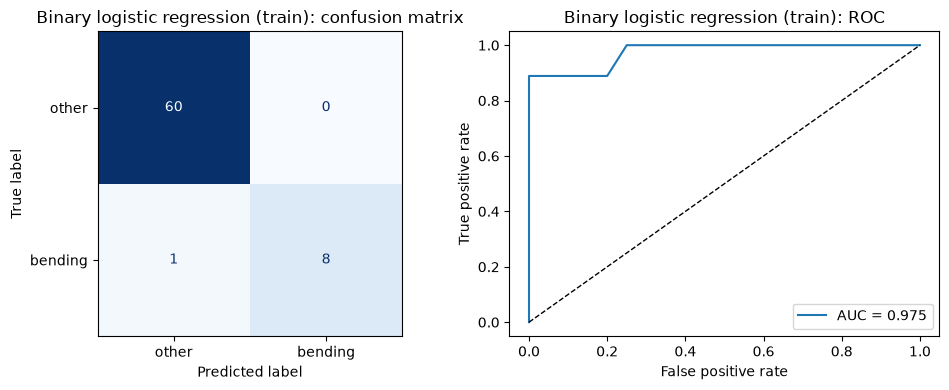

,metric,value
0,five-fold CV accuracy,0.971429
1,train accuracy,0.985507
2,train AUC,0.975000
3,test accuracy,0.894737


The maximum-likelihood fit converged without numerical evidence of complete separation.


In [5]:
def fit_logit_for_inference(
    features: pd.DataFrame, target: pd.Series
) -> tuple[object | None, list[str]]:
    design = sm.add_constant(features, has_constant="add")
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        try:
            fitted = sm.Logit(target, design).fit(disp=False, maxiter=1_000)
        except (PerfectSeparationError, np.linalg.LinAlgError) as error:
            return None, [*(str(item.message) for item in caught), str(error)]
    return fitted, [str(item.message) for item in caught]


def plot_binary_diagnostics(
    truth: np.ndarray,
    probability: np.ndarray,
    title: str,
) -> dict[str, float]:
    prediction = (probability >= 0.5).astype(int)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    ConfusionMatrixDisplay.from_predictions(
        truth,
        prediction,
        display_labels=["other", "bending"],
        cmap="Blues",
        colorbar=False,
        ax=axes[0],
    )
    axes[0].set_title(f"{title}: confusion matrix")
    false_positive_rate, true_positive_rate, _ = roc_curve(truth, probability)
    auc_value = roc_auc_score(truth, probability)
    axes[1].plot(false_positive_rate, true_positive_rate, label=f"AUC = {auc_value:.3f}")
    axes[1].plot([0, 1], [0, 1], "k--", linewidth=1)
    axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title=f"{title}: ROC")
    axes[1].legend(loc="lower right")
    fig.tight_layout()
    plt.show()
    return {
        "accuracy": float(accuracy_score(truth, prediction)),
        "auc": float(auc_value),
    }


binary_scaler = StandardScaler().fit(binary_train[selected_binary_features])
X_binary_train = pd.DataFrame(
    binary_scaler.transform(binary_train[selected_binary_features]),
    columns=selected_binary_features,
)
X_binary_test = pd.DataFrame(
    binary_scaler.transform(binary_test[selected_binary_features]),
    columns=selected_binary_features,
)
y_binary_train = binary_train["bending"].astype(int).reset_index(drop=True)
y_binary_test = binary_test["bending"].astype(int).reset_index(drop=True)

binary_classifier = unpenalized_binary_logistic().fit(X_binary_train, y_binary_train)
binary_train_probability = binary_classifier.predict_proba(X_binary_train)[:, 1]
binary_test_probability = binary_classifier.predict_proba(X_binary_test)[:, 1]
binary_inference_model, binary_fit_messages = fit_logit_for_inference(
    X_binary_train, y_binary_train
)
fit_warning_text = " ".join(binary_fit_messages).lower()
inference_converged = bool(
    getattr(binary_inference_model, "mle_retvals", {}).get(
        "converged", getattr(binary_inference_model, "converged", False)
    )
) if binary_inference_model is not None else False
inference_parameters = (
    np.asarray(binary_inference_model.params)
    if binary_inference_model is not None
    else np.array([])
)
possible_separation = (
    binary_inference_model is None
    or not inference_converged
    or not np.isfinite(inference_parameters).all()
    or float(np.abs(inference_parameters).max(initial=0)) > 25
    or "perfect separation" in fit_warning_text
    or "failed to converge" in fit_warning_text
)

if possible_separation:
    coefficient_table = pd.DataFrame(
        {
            "feature": ["intercept", *selected_binary_features],
            "finite classifier coefficient": [
                float(binary_classifier.intercept_[0]),
                *map(float, binary_classifier.coef_[0]),
            ],
            "MLE p_value": "not identifiable: separation/instability",
        }
    )
else:
    coefficient_table = pd.DataFrame(
        {
            "feature": ["intercept", *selected_binary_features],
            "coefficient": inference_parameters,
            "p_value": np.asarray(binary_inference_model.pvalues),
        }
    )
display(coefficient_table)

train_binary_metrics = plot_binary_diagnostics(
    y_binary_train.to_numpy(), binary_train_probability, "Binary logistic regression (train)"
)
test_binary_accuracy = accuracy_score(y_binary_test, binary_test_probability >= 0.5)
display(
    pd.DataFrame(
        [
            {
                "metric": "five-fold CV accuracy",
                "value": BEST_BINARY_CV_ACCURACY,
            },
            {"metric": "train accuracy", "value": train_binary_metrics["accuracy"]},
            {"metric": "train AUC", "value": train_binary_metrics["auc"]},
            {"metric": "test accuracy", "value": float(test_binary_accuracy)},
        ]
    )
)

if possible_separation:
    print(
        "The maximum-likelihood fit is unstable or non-convergent because the classes are "
        "(near-)separated. Its p-values are not identifiable. The finite coefficients above "
        "are only the bounded-iteration classifier used for prediction."
    )
else:
    print(
        "The maximum-likelihood fit converged without numerical evidence of complete separation."
    )

The test accuracy is 89.47%, 7.67 percentage points below the 97.14%
five-fold CV accuracy. Performance on this fixed test set is therefore lower
than the cross-validation estimate.

### 2(a)(vii) Case-control sampling for the imbalanced binary classes

The training set has 9 bending and 60 other instances.  A one-to-one
case-control sample is fit below.  Its intercept is corrected from the sample
prevalence to the original training prevalence; the slopes are unchanged.

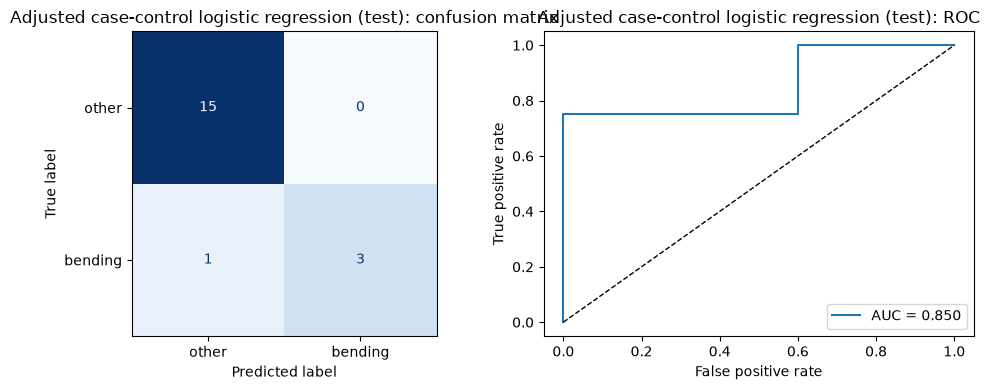

,original training prevalence,case-control prevalence,intercept adjustment,test accuracy,test AUC
0,0.130435,0.5,-1.89712,0.947368,0.85


In [6]:
positive_indices = np.flatnonzero(y_binary_train.to_numpy() == 1)
negative_indices = np.flatnonzero(y_binary_train.to_numpy() == 0)
rng = np.random.default_rng(RANDOM_STATE)
control_indices = rng.choice(negative_indices, size=positive_indices.size, replace=False)
case_control_indices = np.sort(np.concatenate([positive_indices, control_indices]))

case_control_model = unpenalized_binary_logistic().fit(
    X_binary_train.iloc[case_control_indices], y_binary_train.iloc[case_control_indices]
)
population_prevalence = float(y_binary_train.mean())
sample_prevalence = float(y_binary_train.iloc[case_control_indices].mean())
intercept_adjustment = np.log(population_prevalence / (1 - population_prevalence)) - np.log(
    sample_prevalence / (1 - sample_prevalence)
)
adjusted_intercept = float(case_control_model.intercept_[0] + intercept_adjustment)


def adjusted_case_control_probability(features: pd.DataFrame) -> np.ndarray:
    log_odds = features.to_numpy() @ case_control_model.coef_[0] + adjusted_intercept
    return 1 / (1 + np.exp(-log_odds))


case_control_test_probability = adjusted_case_control_probability(X_binary_test)
case_control_metrics = plot_binary_diagnostics(
    y_binary_test.to_numpy(), case_control_test_probability, "Adjusted case-control logistic regression (test)"
)
display(
    pd.DataFrame(
        [
            {
                "original training prevalence": population_prevalence,
                "case-control prevalence": sample_prevalence,
                "intercept adjustment": intercept_adjustment,
                "test accuracy": case_control_metrics["accuracy"],
                "test AUC": case_control_metrics["auc"],
            }
        ]
    )
)

### 2(b) L1-penalized binary logistic regression

This search cross-validates both `l` and `C` (the inverse L1 penalty).  The
scaler is inside the pipeline, so it is fit separately in every CV fold.

In [7]:
C_GRID = np.logspace(-3, 3, 7)


def l1_binary_pipeline(c_value: float) -> Pipeline:
    return Pipeline(
        [
            ("scale", StandardScaler()),
            (
                "model",
                LogisticRegression(
                    C=c_value,
                    l1_ratio=1,
                    solver="liblinear",
                    max_iter=10_000,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )


l1_binary_rows: list[dict[str, float | int]] = []
for n_segments in L_VALUES:
    table = FEATURE_TABLES[n_segments].query("split == 'train'").reset_index(drop=True)
    columns = feature_columns(table)
    for c_value in C_GRID:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=ConvergenceWarning)
            scores = cross_val_score(
                l1_binary_pipeline(float(c_value)),
                table[columns],
                table["bending"],
                cv=BINARY_CV,
                scoring="accuracy",
                n_jobs=1,
            )
        l1_binary_rows.append(
            {
                "l": n_segments,
                "C": float(c_value),
                "cv_accuracy": float(np.mean(scores)),
            }
        )

l1_binary_search = (
    pd.DataFrame(l1_binary_rows)
    .sort_values(["cv_accuracy", "l", "C"], ascending=[False, True, True])
    .reset_index(drop=True)
)
display(l1_binary_search.head(15))

best_l1_binary = l1_binary_search.iloc[0]
BEST_L1_BINARY_L = int(best_l1_binary["l"])
BEST_L1_BINARY_C = float(best_l1_binary["C"])
BEST_L1_BINARY_CV_ACCURACY = float(best_l1_binary["cv_accuracy"])
l1_binary_train = FEATURE_TABLES[BEST_L1_BINARY_L].query("split == 'train'").reset_index(drop=True)
l1_binary_test = FEATURE_TABLES[BEST_L1_BINARY_L].query("split == 'test'").reset_index(drop=True)
l1_binary_columns = feature_columns(l1_binary_train)
l1_binary_model = l1_binary_pipeline(BEST_L1_BINARY_C).fit(
    l1_binary_train[l1_binary_columns], l1_binary_train["bending"]
)
l1_binary_test_accuracy = accuracy_score(
    l1_binary_test["bending"], l1_binary_model.predict(l1_binary_test[l1_binary_columns])
)
l1_nonzero = int(np.count_nonzero(l1_binary_model.named_steps["model"].coef_[0]))

display(
    pd.DataFrame(
        [
            {
                "method": "RFE + near-unpenalized logistic",
                "l": BEST_BINARY_L,
                "selected features": BEST_BINARY_P,
                "CV accuracy": BEST_BINARY_CV_ACCURACY,
                "test accuracy": float(test_binary_accuracy),
            },
            {
                "method": "L1 logistic",
                "l": BEST_L1_BINARY_L,
                "selected features": l1_nonzero,
                "CV accuracy": BEST_L1_BINARY_CV_ACCURACY,
                "test accuracy": float(l1_binary_test_accuracy),
            },
        ]
    )
)
print(
    "L1 selection is easier to implement because coefficient shrinkage and selection occur in one model; "
    "RFE explicitly refits multiple reduced feature sets."
)

,l,C,cv_accuracy
0,11,1.0,0.985714
1,11,10.0,0.985714
2,12,1.0,0.985714
3,12,10.0,0.985714
4,18,10.0,0.985714
5,1,1.0,0.971429
6,13,1.0,0.971429
7,18,1.0,0.971429
8,18,100.0,0.971429
9,19,1.0,0.971429


,method,l,selected features,CV accuracy,test accuracy
0,RFE + near-unpenalized logistic,3,1,0.971429,0.894737
1,L1 logistic,11,8,0.985714,0.947368


L1 selection is easier to implement because coefficient shrinkage and selection occur in one model; RFE explicitly refits multiple reduced feature sets.


L1 logistic achieves 98.57% CV accuracy and 94.74% test accuracy, versus
97.14% and 89.47% for RFE: improvements of 1.43 and 5.26 percentage points,
respectively, on these samples.

### 2(c)(i) L1-penalized multinomial logistic regression

`bending2` has only four training observations, so a 5-fold multiclass split
would leave a validation fold without that class.  Stratified 4-fold CV keeps
every activity represented in every fold while selecting `l` and `C`.
Multiclass ROC below is one-versus-rest: each curve treats one activity as
positive and the other six as negative; the macro AUC is their unweighted mean.

,l,C,cv_accuracy
0,2,1000.0,0.927288
1,2,100.0,0.912582
2,1,1.0,0.900327
3,1,100.0,0.898693
4,1,1000.0,0.898693
5,2,10.0,0.898693
6,3,100.0,0.897876
7,3,1000.0,0.897876
8,4,100.0,0.897876
9,4,1000.0,0.897876


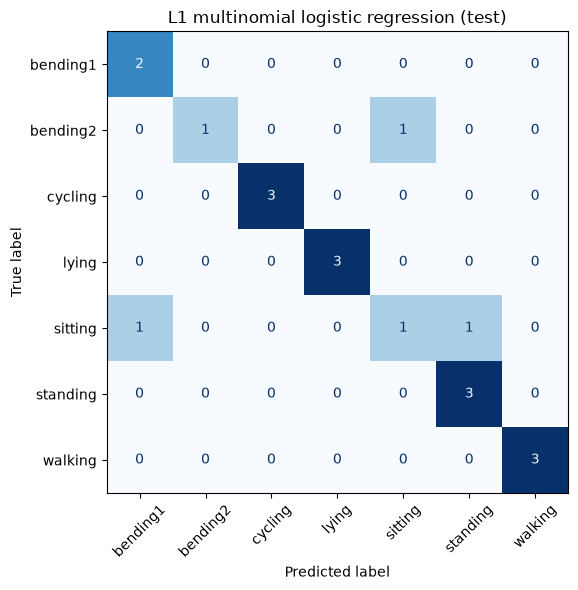

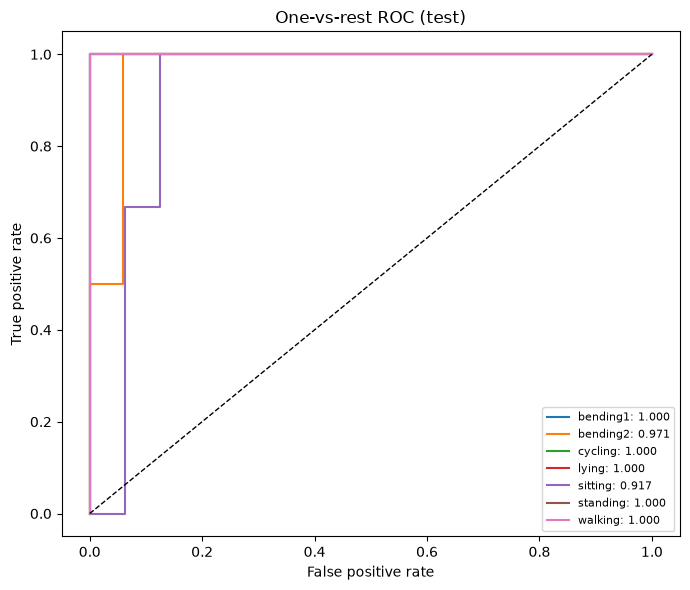

,activity,one_vs_rest_auc
0,bending1,1.000000
1,bending2,0.970588
2,cycling,1.000000
3,lying,1.000000
4,sitting,0.916667
5,standing,1.000000
6,walking,1.000000


,l,C,CV accuracy,test accuracy,test error,macro one-vs-rest AUC
0,2,1000.0,0.927288,0.842105,0.157895,0.983894


In [8]:
MULTICLASS_CV = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)


def l1_multinomial_pipeline(c_value: float) -> Pipeline:
    return Pipeline(
        [
            ("scale", StandardScaler()),
            (
                "model",
                LogisticRegression(
                    C=c_value,
                    l1_ratio=1,
                    solver="saga",
                    max_iter=10_000,
                    tol=1e-3,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    )


multinomial_rows: list[dict[str, float | int]] = []
for n_segments in L_VALUES:
    table = FEATURE_TABLES[n_segments].query("split == 'train'").reset_index(drop=True)
    columns = feature_columns(table)
    for c_value in C_GRID:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=ConvergenceWarning)
            warnings.simplefilter("ignore", category=FutureWarning)
            scores = cross_val_score(
                l1_multinomial_pipeline(float(c_value)),
                table[columns],
                table["activity"],
                cv=MULTICLASS_CV,
                scoring="accuracy",
                n_jobs=1,
            )
        multinomial_rows.append(
            {
                "l": n_segments,
                "C": float(c_value),
                "cv_accuracy": float(np.mean(scores)),
            }
        )

multinomial_search = (
    pd.DataFrame(multinomial_rows)
    .sort_values(["cv_accuracy", "l", "C"], ascending=[False, True, True])
    .reset_index(drop=True)
)
display(multinomial_search.head(15))

best_multinomial = multinomial_search.iloc[0]
BEST_MULTINOMIAL_L = int(best_multinomial["l"])
BEST_MULTINOMIAL_C = float(best_multinomial["C"])
BEST_MULTINOMIAL_CV_ACCURACY = float(best_multinomial["cv_accuracy"])
multinomial_train = FEATURE_TABLES[BEST_MULTINOMIAL_L].query("split == 'train'").reset_index(drop=True)
multinomial_test = FEATURE_TABLES[BEST_MULTINOMIAL_L].query("split == 'test'").reset_index(drop=True)
multinomial_columns = feature_columns(multinomial_train)
multinomial_model = l1_multinomial_pipeline(BEST_MULTINOMIAL_C).fit(
    multinomial_train[multinomial_columns], multinomial_train["activity"]
)
multinomial_prediction = multinomial_model.predict(multinomial_test[multinomial_columns])
multinomial_probability = multinomial_model.predict_proba(multinomial_test[multinomial_columns])
multinomial_classes = multinomial_model.named_steps["model"].classes_
multinomial_test_accuracy = accuracy_score(multinomial_test["activity"], multinomial_prediction)
multinomial_test_error = 1 - multinomial_test_accuracy

fig, axis = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    multinomial_test["activity"],
    multinomial_prediction,
    labels=multinomial_classes,
    cmap="Blues",
    colorbar=False,
    xticks_rotation=45,
    ax=axis,
)
axis.set_title("L1 multinomial logistic regression (test)")
fig.tight_layout()
plt.show()

multinomial_auc_rows: list[dict[str, float | str]] = []
fig, axis = plt.subplots(figsize=(7, 6))
for class_index, activity in enumerate(multinomial_classes):
    class_truth = (multinomial_test["activity"].to_numpy() == activity).astype(int)
    false_positive_rate, true_positive_rate, _ = roc_curve(
        class_truth, multinomial_probability[:, class_index]
    )
    class_auc = auc(false_positive_rate, true_positive_rate)
    multinomial_auc_rows.append({"activity": activity, "one_vs_rest_auc": class_auc})
    axis.plot(false_positive_rate, true_positive_rate, label=f"{activity}: {class_auc:.3f}")
axis.plot([0, 1], [0, 1], "k--", linewidth=1)
axis.set(xlabel="False positive rate", ylabel="True positive rate", title="One-vs-rest ROC (test)")
axis.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

multinomial_auc = pd.DataFrame(multinomial_auc_rows)
macro_auc = float(multinomial_auc["one_vs_rest_auc"].mean())
display(multinomial_auc)
display(
    pd.DataFrame(
        [
            {
                "l": BEST_MULTINOMIAL_L,
                "C": BEST_MULTINOMIAL_C,
                "CV accuracy": BEST_MULTINOMIAL_CV_ACCURACY,
                "test accuracy": float(multinomial_test_accuracy),
                "test error": float(multinomial_test_error),
                "macro one-vs-rest AUC": macro_auc,
            }
        ]
    )
)

### 2(c)(ii)--(iii) Gaussian and Multinomial Naive Bayes

Each Naive Bayes model selects `l` by the same stratified 4-fold procedure.
MultinomialNB requires nonnegative inputs, so its min-max transform is fitted
inside each fold and clipped for test values outside the training range.

,l,cv_accuracy
0,1,0.870098
1,2,0.856209
2,5,0.754085
3,3,0.753268
4,4,0.710784
5,6,0.680556
6,10,0.680556
7,7,0.665850
8,11,0.652778
9,8,0.635621


,l,cv_accuracy
0,1,0.782680
1,3,0.753268
2,2,0.752451
3,5,0.752451
4,6,0.738562
5,8,0.738562
6,9,0.738562
7,7,0.737745
8,4,0.723856
9,13,0.723039


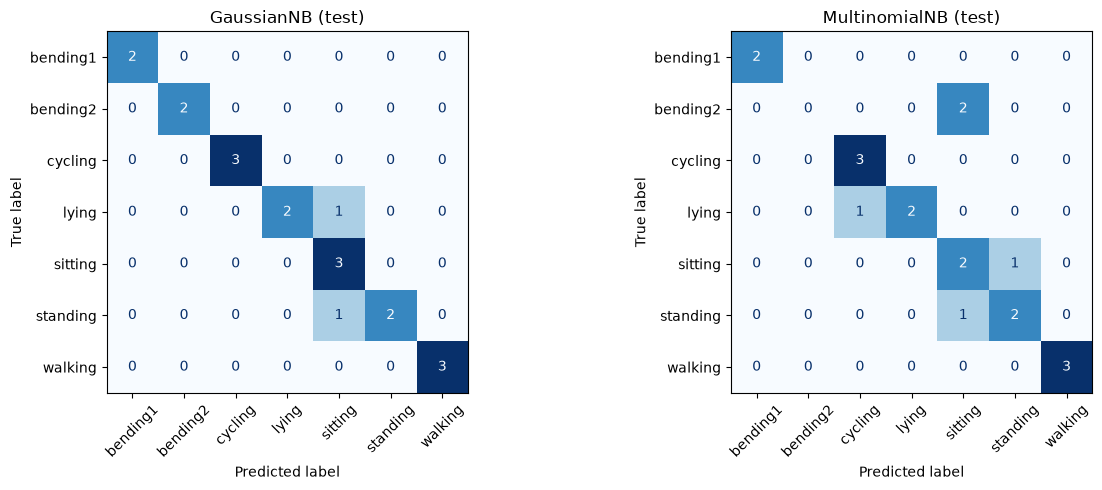

,method,l,CV accuracy,test error
0,Gaussian Naive Bayes,1,0.870098,0.105263
1,L1 multinomial logistic regression,2,0.927288,0.157895
2,Multinomial Naive Bayes,1,0.782680,0.263158


On this fixed test set, Gaussian Naive Bayes has the lowest observed test error. This comparison is specific to the given split.


In [9]:
def gaussian_nb_pipeline() -> Pipeline:
    return Pipeline([("scale", StandardScaler()), ("model", GaussianNB())])


def multinomial_nb_pipeline() -> Pipeline:
    return Pipeline(
        [("scale", MinMaxScaler(clip=True)), ("model", MultinomialNB())]
    )


def select_naive_bayes(make_model) -> pd.DataFrame:
    rows: list[dict[str, float | int]] = []
    for n_segments in L_VALUES:
        table = FEATURE_TABLES[n_segments].query("split == 'train'").reset_index(drop=True)
        columns = feature_columns(table)
        scores = cross_val_score(
            make_model(),
            table[columns],
            table["activity"],
            cv=MULTICLASS_CV,
            scoring="accuracy",
            n_jobs=1,
        )
        rows.append({"l": n_segments, "cv_accuracy": float(np.mean(scores))})
    return pd.DataFrame(rows).sort_values(["cv_accuracy", "l"], ascending=[False, True]).reset_index(
        drop=True
    )


gaussian_search = select_naive_bayes(gaussian_nb_pipeline)
multinomial_nb_search = select_naive_bayes(multinomial_nb_pipeline)
display(gaussian_search)
display(multinomial_nb_search)


def fit_naive_bayes(best_l: int, make_model) -> tuple[Pipeline, pd.DataFrame, np.ndarray, float]:
    train_table = FEATURE_TABLES[best_l].query("split == 'train'").reset_index(drop=True)
    test_table = FEATURE_TABLES[best_l].query("split == 'test'").reset_index(drop=True)
    columns = feature_columns(train_table)
    model = make_model().fit(train_table[columns], train_table["activity"])
    prediction = model.predict(test_table[columns])
    test_error = float(1 - accuracy_score(test_table["activity"], prediction))
    return model, test_table, prediction, test_error


BEST_GAUSSIAN_L = int(gaussian_search.iloc[0]["l"])
BEST_MULTINOMIAL_NB_L = int(multinomial_nb_search.iloc[0]["l"])
gaussian_model, gaussian_test, gaussian_prediction, gaussian_test_error = fit_naive_bayes(
    BEST_GAUSSIAN_L, gaussian_nb_pipeline
)
multinomial_nb_model, multinomial_nb_test, multinomial_nb_prediction, multinomial_nb_test_error = fit_naive_bayes(
    BEST_MULTINOMIAL_NB_L, multinomial_nb_pipeline
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(
    gaussian_test["activity"],
    gaussian_prediction,
    labels=ACTIVITIES,
    cmap="Blues",
    colorbar=False,
    xticks_rotation=45,
    ax=axes[0],
)
axes[0].set_title("GaussianNB (test)")
ConfusionMatrixDisplay.from_predictions(
    multinomial_nb_test["activity"],
    multinomial_nb_prediction,
    labels=ACTIVITIES,
    cmap="Blues",
    colorbar=False,
    xticks_rotation=45,
    ax=axes[1],
)
axes[1].set_title("MultinomialNB (test)")
fig.tight_layout()
plt.show()

multiclass_comparison = pd.DataFrame(
    [
        {
            "method": "L1 multinomial logistic regression",
            "l": BEST_MULTINOMIAL_L,
            "CV accuracy": BEST_MULTINOMIAL_CV_ACCURACY,
            "test error": float(multinomial_test_error),
        },
        {
            "method": "Gaussian Naive Bayes",
            "l": BEST_GAUSSIAN_L,
            "CV accuracy": float(gaussian_search.iloc[0]["cv_accuracy"]),
            "test error": gaussian_test_error,
        },
        {
            "method": "Multinomial Naive Bayes",
            "l": BEST_MULTINOMIAL_NB_L,
            "CV accuracy": float(multinomial_nb_search.iloc[0]["cv_accuracy"]),
            "test error": multinomial_nb_test_error,
        },
    ]
).sort_values("test error").reset_index(drop=True)
display(multiclass_comparison)
best_multiclass_method = str(multiclass_comparison.iloc[0]["method"])
print(
    f"On this fixed test set, {best_multiclass_method} has the lowest observed test error. "
    "This comparison is specific to the given split."
)

Gaussian Naive Bayes has the lowest error on this fixed test set (10.53%),
compared with L1 multinomial logistic regression (15.79%) and Multinomial
Naive Bayes (26.32%). The CV ranking differs: L1 logistic has 92.73% accuracy
versus 87.01% for Gaussian Naive Bayes, so the test-set ranking may not
generalize.

## 3. ISLR (2nd edition) 4.8.3

With one feature, the QDA posterior for class $k$ is proportional to

$$\pi_k\sigma_k^{-1}\exp\left[-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right].$$

Dropping the common constant and taking logs gives

$$\delta_k(x)=-\frac{x^2}{2\sigma_k^2}+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}-\frac12\log(\sigma_k^2)+\log(\pi_k).$$

The $x^2$ coefficient depends on $k$ when the class variances differ, so
comparing class discriminants yields quadratic decision boundaries.  If all
variances were equal, the common $x^2$ term would cancel and the boundary
would be linear.

## 4. ISLR (2nd edition) 4.8.7

Let $D$ denote issuing a dividend.  With $P(D)=0.8$, $P(D^c)=0.2$,
$μ_D=10$, $μ_{D^c}=0$, and $σ^2=36$,

$$P(D\mid X=4)=\frac{0.8\,\phi(4;10,36)}{0.8\,\phi(4;10,36)+0.2\,\phi(4;0,36)}
=\frac{4e^{-5/18}}{1+4e^{-5/18}}\approx 0.7519.$$

Therefore, the predicted probability is about **75.2%**.